# RecruitGen — Model 3 of 3: Transformer V3 (Fast, resumable training)

Transformer V3 classifies resume text into job roles using DistilBERT plus nine numerical features.

This version is configured for **70 epochs**, progress bars, CUDA mixed precision when available, optional partial encoder freezing, and Drive checkpoints saved after every epoch. It writes to a new folder (`MyDrive/TransformerV3_FastTraining`) so it does not overwrite the older run.

**Important:** runtime depends on the GPU, dataset size, and Colab availability; 50 epochs cannot be guaranteed to finish within one hour. Accuracy/loss depend on the data and are not guaranteed. If using generated synthetic resumes, evaluation scores may not represent performance on real resumes.


## 1. Setup

In [1]:
# Google Colab setup: mount Drive and locate feature_extractor.py
from google.colab import drive
drive.mount('/content/drive')

import os, sys
DRIVE_PROJECT_DIR = '/content/drive/MyDrive/Colab Notebooks'
if DRIVE_PROJECT_DIR not in sys.path:
    sys.path.insert(0, DRIVE_PROJECT_DIR)
FEATURE_EXTRACTOR_PATH = os.path.join(DRIVE_PROJECT_DIR, 'feature_extractor.py')
if not os.path.exists(FEATURE_EXTRACTOR_PATH):
    raise FileNotFoundError(
        f'feature_extractor.py not found at {FEATURE_EXTRACTOR_PATH}. '
        'Upload it to Google Drive > MyDrive > Colab Notebooks, then rerun this cell.'
    )
print('Drive mounted; feature extractor found:', FEATURE_EXTRACTOR_PATH)


Mounted at /content/drive
Drive mounted; feature extractor found: /content/drive/MyDrive/Colab Notebooks/feature_extractor.py


In [2]:
import os, json, random, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoTokenizer, DistilBertModel
from safetensors.torch import save_file
from feature_extractor import extract_features

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
QUICK_RUN = False
SAMPLES_PER_ROLE = 12 if QUICK_RUN else 400
EPOCHS = 70
BATCH_SIZE = 16
MAX_LENGTH = 128
LR = 2e-5

# Use a separate Drive folder so this run does not overwrite the older notebook's outputs.
OUTPUT_DIR = "/content/drive/MyDrive/TransformerV3_FastTraining"
os.makedirs(OUTPUT_DIR, exist_ok=True)
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "latest_checkpoint.pt")
BEST_PATH = os.path.join(OUTPUT_DIR, "best_state.pt")
HISTORY_PATH = os.path.join(OUTPUT_DIR, "training_history.json")
RESUME_FROM_CHECKPOINT = False

ROLES = ["AI/ML Engineer", "Cloud Engineer", "Data Analyst", "General IT", "Software Engineer"]
FEATURES = ["experience_years", "projects_count", "programming_score", "data_analytics_score", "ml_ai_score",
            "cloud_score", "communication_score", "certification_count", "education_level"]

# Optional real dataset: if it exists in the current runtime, use it; otherwise generate synthetic profiles.
DATA_PATH = "data/resumes.csv"
USE_AMP = DEVICE.type == "cuda"
FREEZE_FIRST_4_LAYERS = True  # faster fine-tuning; set False to fine-tune all DistilBERT layers
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
print("Device:", DEVICE, "| AMP:", USE_AMP, "| epochs:", EPOCHS)
print("Output/checkpoint folder:", OUTPUT_DIR)


Device: cuda | AMP: True | epochs: 70
Output/checkpoint folder: /content/drive/MyDrive/TransformerV3_FastTraining


## 2. Transformer candidate data — textual profiles

Candidate information (Skills, Experience, Education, Certifications, Job Role, Projects) is converted into
textual resume profiles. A real dataset can be supplied as `data/resumes.csv`.

In [3]:
ROLE_SKILLS = {
    "AI/ML Engineer": ["Python", "TensorFlow", "PyTorch", "machine learning", "deep learning", "NLP", "computer vision", "scikit-learn", "LLMs", "model deployment"],
    "Cloud Engineer": ["AWS", "Azure", "GCP", "Docker", "Kubernetes", "Terraform", "CI/CD", "Linux", "networking", "DevOps"],
    "Data Analyst": ["SQL", "Excel", "Power BI", "Tableau", "Pandas", "statistics", "data visualization", "dashboards", "reporting", "A/B testing"],
    "General IT": ["IT support", "troubleshooting", "Windows", "networking", "help desk", "hardware", "Active Directory", "ticketing", "MS Office", "system administration"],
    "Software Engineer": ["Java", "Python", "JavaScript", "React", "Node.js", "REST APIs", "Spring Boot", "data structures", "algorithms", "Git"],
}
TITLES = {"AI/ML Engineer": ["Machine Learning Engineer", "AI Engineer", "Data Scientist"],
          "Cloud Engineer": ["Cloud Engineer", "DevOps Engineer", "Site Reliability Engineer"],
          "Data Analyst": ["Data Analyst", "Business Analyst", "BI Analyst"],
          "General IT": ["IT Support Specialist", "System Administrator", "IT Technician"],
          "Software Engineer": ["Software Engineer", "Backend Developer", "Full Stack Developer"]}
CERTS = {"AI/ML Engineer": ["TensorFlow Developer Certificate", "AWS Certified Machine Learning", "Deep Learning Specialization"],
         "Cloud Engineer": ["AWS Certified Solutions Architect", "Azure Administrator", "Certified Kubernetes Administrator"],
         "Data Analyst": ["Google Data Analytics Certificate", "Microsoft Power BI Certification", "Tableau Desktop Specialist"],
         "General IT": ["CompTIA A+", "CCNA", "ITIL Foundation"],
         "Software Engineer": ["Oracle Java Certification", "Meta Front-End Developer", "AWS Certified Developer"]}
DEGREES = ["Diploma in Computer Engineering", "B.Tech in Computer Science", "B.Sc in Information Technology",
           "M.Tech in Computer Science", "MCA", "PhD in Computer Science"]

def make_resume(role):
    exp = round(random.uniform(0, 9), 1)
    skills = random.sample(ROLE_SKILLS[role], random.randint(4, 8))
    other = random.choice([r for r in ROLES if r != role])
    skills += random.sample(ROLE_SKILLS[other], random.randint(0, 2))
    projects = random.randint(1, 6)
    certs = random.sample(CERTS[role], random.randint(0, 3))
    soft = random.sample(["communication", "teamwork", "leadership", "presentation", "collaboration"], random.randint(0, 3))
    text = (f"{random.choice(TITLES[role])} with {exp} years of experience. Skills: {', '.join(skills)}. "
            f"Completed {projects} projects including {random.choice(ROLE_SKILLS[role])} and {random.choice(ROLE_SKILLS[role])} work. "
            f"Education: {random.choice(DEGREES)}. ")
    if certs:
        text += "Certifications: " + ", ".join(certs) + ". "
    if soft:
        text += "Strong " + " and ".join(soft) + " skills."
    return text

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)[["resume_text", "role"]]
else:
    df = pd.DataFrame([{"resume_text": make_resume(r), "role": r} for r in ROLES for _ in range(SAMPLES_PER_ROLE)])
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
df.head()

,resume_text,role
0,Full Stack Developer with 8.2 years of experie...,Software Engineer
1,AI Engineer with 7.0 years of experience. Skil...,AI/ML Engineer
2,IT Support Specialist with 0.1 years of experi...,General IT
3,Business Analyst with 0.5 years of experience....,Data Analyst
4,IT Support Specialist with 5.4 years of experi...,General IT


## 3. Rule-based feature extraction → 9 numerical features (fixed order)

In [4]:
feats = pd.DataFrame([extract_features(t) for t in df["resume_text"]])[FEATURES]
df = pd.concat([df, feats], axis=1)
df["label"] = df["role"].map({r: i for i, r in enumerate(ROLES)})

mean, scale = feats.mean().values, feats.std(ddof=0).replace(0, 1).values     # StandardScaler statistics
df[FEATURES].describe().round(2)

,experience_years,projects_count,programming_score,data_analytics_score,ml_ai_score,cloud_score,communication_score,certification_count,education_level
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,4.52,3.53,24.14,21.48,20.38,19.97,50.16,1.47,2.61
std,2.59,1.69,32.45,37.28,35.94,26.26,7.15,1.11,1.23
min,0.00,1.00,0.00,0.00,0.00,0.00,40.00,0.00,1.00
25%,2.40,2.00,0.00,0.00,0.00,0.00,50.00,1.00,2.00
50%,4.50,4.00,15.00,0.00,0.00,15.00,50.00,1.00,2.00
75%,6.80,5.00,30.00,30.00,15.00,30.00,60.00,2.00,3.00
max,9.00,6.00,100.00,100.00,100.00,100.00,60.00,3.00,5.00


In [5]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["label"])
train_df, val_df = train_test_split(train_df, test_size=0.125, random_state=SEED, stratify=train_df["label"])
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

class ResumeDataset(Dataset):
    def __init__(self, frame):
        enc = tokenizer(list(frame["resume_text"]), padding="max_length", truncation=True,
                        max_length=MAX_LENGTH, return_tensors="pt")
        self.ids, self.mask = enc["input_ids"], enc["attention_mask"]
        self.num = torch.tensor(((frame[FEATURES].values - mean) / scale).astype("float32"))
        self.y = torch.tensor(frame["label"].values, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.ids[i], self.mask[i], self.num[i], self.y[i]

loader_kwargs = {"num_workers": NUM_WORKERS, "pin_memory": DEVICE.type == "cuda"}
if NUM_WORKERS > 0:
    loader_kwargs["persistent_workers"] = True
loaders = {
    name: DataLoader(ResumeDataset(frame), batch_size=BATCH_SIZE,
                     shuffle=(name == "train"), **loader_kwargs)
    for name, frame in [("train", train_df), ("val", val_df), ("test", test_df)]
}
print({k: len(v.dataset) for k, v in loaders.items()})


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

{'train': 1400, 'val': 200, 'test': 400}


## 4. Model — DistilBERT text encoder + feature network + fusion classifier

In [6]:
class RecruitGenTransformerV3(nn.Module):
    def __init__(self, num_features=9, hidden_dim=128, num_roles=5):
        super().__init__()
        self.bert = DistilBertModel.from_pretrained("distilbert-base-uncased")
        if FREEZE_FIRST_4_LAYERS:
            for p in self.bert.embeddings.parameters():
                p.requires_grad = False
            for layer in self.bert.transformer.layer[:4]:
                for p in layer.parameters():
                    p.requires_grad = False
        self.text_projection = nn.Sequential(nn.Linear(self.bert.config.hidden_size, hidden_dim), nn.ReLU(), nn.Dropout(0.2))
        self.feature_network = nn.Sequential(
            nn.Linear(num_features, 64), nn.ReLU(), nn.BatchNorm1d(64), nn.Dropout(0.2),
            nn.Linear(64, hidden_dim), nn.ReLU(), nn.Dropout(0.2))
        self.fusion = nn.Sequential(nn.Linear(hidden_dim * 2, hidden_dim), nn.ReLU(), nn.Dropout(0.2))
        self.classifier = nn.Linear(hidden_dim, num_roles)

    def forward(self, input_ids, attention_mask, numerical_features):
        cls = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        fused = torch.cat([self.text_projection(cls), self.feature_network(numerical_features)], dim=1)
        return self.classifier(self.fusion(fused))

model = RecruitGenTransformerV3(num_roles=len(ROLES)).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Parameters: 66,503,941
Trainable parameters: 14,316,805


## 5. Training

In [7]:
optimizer = torch.optim.AdamW(
    (p for p in model.parameters() if p.requires_grad), lr=LR, weight_decay=0.01
)
total_steps = EPOCHS * len(loaders["train"])
warmup_steps = max(1, int(0.1 * total_steps))
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lambda step: min(
        (step + 1) / warmup_steps,
        max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))
    )
)
loss_fn = nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

history = []
best = 0.0
start_epoch = 1

# Resume only from this notebook's separate checkpoint folder.
if RESUME_FROM_CHECKPOINT and os.path.exists(CHECKPOINT_PATH):
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    scheduler.load_state_dict(checkpoint["scheduler_state"])
    if "scaler_state" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler_state"])
    history = checkpoint.get("history", [])
    best = checkpoint.get("best_accuracy", 0.0)
    start_epoch = int(checkpoint.get("epoch", 0)) + 1
    print(f"Resuming from epoch {start_epoch}; best validation accuracy so far: {best:.4f}")
else:
    print("Starting a new training run.")

def run_epoch(loader, train, epoch_num=None):
    model.train(train)
    total_loss, preds, labels = 0.0, [], []
    phase = "Train" if train else ("Validation" if loader is loaders["val"] else "Test")
    progress = tqdm(loader, desc=f"{phase}", leave=False)
    for ids, mask, num, y in progress:
        ids = ids.to(DEVICE, non_blocking=True)
        mask = mask.to(DEVICE, non_blocking=True)
        num = num.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True) if train else None

        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(ids, mask, num)
                loss = loss_fn(logits, y)
            if train:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(
                    (p for p in model.parameters() if p.requires_grad), 1.0
                )
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()

        total_loss += loss.item() * len(y)
        preds.extend(logits.detach().argmax(1).cpu().tolist())
        labels.extend(y.detach().cpu().tolist())
        progress.set_postfix(loss=f"{loss.item():.4f}")
    return total_loss / len(loader.dataset), accuracy_score(labels, preds), preds, labels

for epoch in range(start_epoch, EPOCHS + 1):
    epoch_start = time.time()
    tl, ta, *_ = run_epoch(loaders["train"], True, epoch)
    vl, va, *_ = run_epoch(loaders["val"], False, epoch)
    elapsed = time.time() - epoch_start
    history.append({"epoch": epoch, "train_loss": tl, "val_loss": vl,
                    "train_accuracy": ta, "val_accuracy": va, "seconds": elapsed})

    improved = va >= best
    if improved:
        best = va
        torch.save(model.state_dict(), BEST_PATH)

    # Full checkpoint means the next run can continue after a Colab disconnect.
    torch.save({
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "history": history,
        "best_accuracy": best,
        "seed": SEED
    }, CHECKPOINT_PATH)
    with open(HISTORY_PATH, "w", encoding="utf-8") as f:
        json.dump(history, f, indent=2)

    avg_seconds = np.mean([h["seconds"] for h in history[-5:]])
    remaining = max(0, EPOCHS - epoch)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | "
          f"val loss {vl:.4f} acc {va:.4f} | best val acc {best:.4f} | "
          f"{elapsed:.1f}s | ETA ~{remaining * avg_seconds / 60:.1f} min")
    print("Checkpoint saved to Drive:", CHECKPOINT_PATH)

if not os.path.exists(BEST_PATH):
    raise FileNotFoundError("Best model checkpoint was not created. Check training output above.")
model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE, weights_only=True))


Starting a new training run.


Train:   0%|          | 0/88 [00:00<?, ?it/s]

Validation:   0%|          | 0/13 [00:00<?, ?it/s]

Epoch 01/70 | train loss 1.6125 acc 0.2014 | val loss 1.6023 acc 0.2900 | best val acc 0.2900 | 5.5s | ETA ~6.3 min
Checkpoint saved to Drive: /content/drive/MyDrive/TransformerV3_FastTraining/latest_checkpoint.pt


Train:   0%|          | 0/88 [00:00<?, ?it/s]

Validation:   0%|          | 0/13 [00:00<?, ?it/s]

... (202 outputs left out)

Train:   0%|          | 0/88 [00:00<?, ?it/s]

Validation:   0%|          | 0/13 [00:00<?, ?it/s]

Epoch 70/70 | train loss 0.0003 acc 1.0000 | val loss 0.0001 acc 1.0000 | best val acc 1.0000 | 3.4s | ETA ~0.0 min
Checkpoint saved to Drive: /content/drive/MyDrive/TransformerV3_FastTraining/latest_checkpoint.pt


<All keys matched successfully>

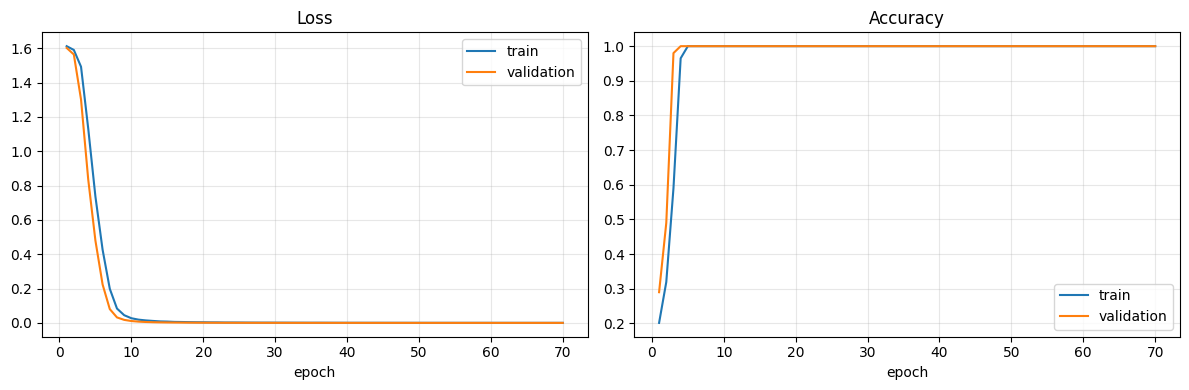

In [8]:
if history:
    hist_df = pd.DataFrame(history)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist_df["epoch"], hist_df["train_loss"], label="train")
    ax[0].plot(hist_df["epoch"], hist_df["val_loss"], label="validation")
    ax[0].set_title("Loss")
    ax[1].plot(hist_df["epoch"], hist_df["train_accuracy"], label="train")
    ax[1].plot(hist_df["epoch"], hist_df["val_accuracy"], label="validation")
    ax[1].set_title("Accuracy")
    for a in ax:
        a.legend(); a.grid(alpha=0.3); a.set_xlabel("epoch")
    plt.tight_layout(); plt.show()
else:
    print("No completed epochs yet.")


## 6. Evaluation — Accuracy · Precision · Recall · F1 · Confusion matrix

Test:   0%|          | 0/25 [00:00<?, ?it/s]

Test accuracy: 1.0000

                   precision    recall  f1-score   support

   AI/ML Engineer     1.0000    1.0000    1.0000        80
   Cloud Engineer     1.0000    1.0000    1.0000        80
     Data Analyst     1.0000    1.0000    1.0000        80
       General IT     1.0000    1.0000    1.0000        80
Software Engineer     1.0000    1.0000    1.0000        80

         accuracy                         1.0000       400
        macro avg     1.0000    1.0000    1.0000       400
     weighted avg     1.0000    1.0000    1.0000       400



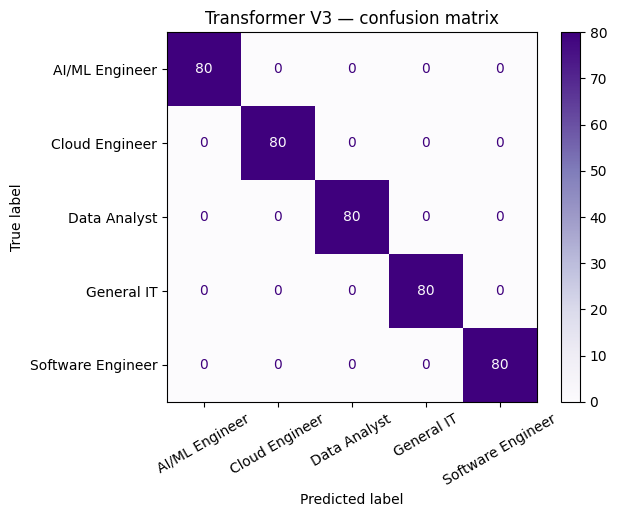

In [9]:
_, test_acc, preds, labels = run_epoch(loaders["test"], False)
print(f"Test accuracy: {test_acc:.4f}\n")
print(classification_report(labels, preds, labels=list(range(len(ROLES))), target_names=ROLES, digits=4, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(labels, preds, labels=list(range(len(ROLES)))), display_labels=ROLES).plot(xticks_rotation=30, cmap="Purples")
plt.title("Transformer V3 — confusion matrix"); plt.show()

## 7. Role prediction with confidence (PPT example)

In [10]:
def predict(text):
    f = extract_features(text)
    num = torch.tensor(((np.array([f[k] for k in FEATURES]) - mean) / scale)[None].astype("float32")).to(DEVICE)
    enc = tokenizer(text, padding="max_length", truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(DEVICE)
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(enc["input_ids"], enc["attention_mask"], num), 1)[0].cpu().numpy()
    return f, ROLES[int(p.argmax())], float(p.max() * 100), dict(zip(ROLES, (p * 100).round(2)))

example = "Machine Learning Engineer with 1.5 years of experience. Python, TensorFlow, PyTorch, SQL, AWS. B.Tech in Computer Science. 4 projects. TensorFlow Developer Certificate."
features, role, conf, probs = predict(example)
print("Features :", features)
print(f"Predicted: {role}  (confidence {conf:.2f}%)")
probs

Features : {'experience_years': 1.5, 'projects_count': 4, 'programming_score': 30.0, 'data_analytics_score': 15.0, 'ml_ai_score': 45.0, 'cloud_score': 15.0, 'communication_score': 50.0, 'certification_count': 0, 'education_level': 2}
Predicted: AI/ML Engineer  (confidence 99.99%)


{'AI/ML Engineer': np.float32(99.99),
 'Cloud Engineer': np.float32(0.0),
 'Data Analyst': np.float32(0.0),
 'General IT': np.float32(0.0),
 'Software Engineer': np.float32(0.0)}

## 8. Semantic similarity — cosine similarity between resume and job-role embeddings

In [11]:
ROLE_DESCRIPTIONS = {r: f"{TITLES[r][0]} skilled in " + ", ".join(ROLE_SKILLS[r]) for r in ROLES}

@torch.no_grad()
def embed(texts):
    enc = tokenizer(texts, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(DEVICE)
    out = model.bert(**enc).last_hidden_state
    m = enc["attention_mask"].unsqueeze(-1)
    return torch.nn.functional.normalize((out * m).sum(1) / m.sum(1), dim=1)

sims = (embed([example]) @ embed(list(ROLE_DESCRIPTIONS.values())).T)[0].cpu().numpy()
pd.DataFrame({"Role": ROLES, "Cosine similarity": sims.round(4)}).sort_values("Cosine similarity", ascending=False)

,Role,Cosine similarity
0,AI/ML Engineer,0.9448
4,Software Engineer,0.4628
2,Data Analyst,0.4474
1,Cloud Engineer,0.3272
3,General IT,0.2283


## 9. Export — `model.safetensors` · `config.json` · `scaler.json` · `tokenizer/`

In [12]:
state = {k: (v.half() if v.is_floating_point() else v).contiguous().cpu()
         for k, v in model.state_dict().items()}
save_file(state, os.path.join(OUTPUT_DIR, "model.safetensors"),
          metadata={"format": "pt", "model": "RecruitGenTransformerV3"})
with open(os.path.join(OUTPUT_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump({"model_name": "RecruitGenTransformerV3",
               "base_transformer": "distilbert-base-uncased", "hidden_dim": 128,
               "num_features": 9, "num_roles": len(ROLES), "max_length": MAX_LENGTH,
               "role_names": ROLES, "feature_order": FEATURES,
               "freeze_first_4_layers": FREEZE_FIRST_4_LAYERS}, f, indent=2)
with open(os.path.join(OUTPUT_DIR, "scaler.json"), "w", encoding="utf-8") as f:
    json.dump({"mean": mean.tolist(), "scale": scale.tolist()}, f, indent=2)
tokenizer.save_pretrained(os.path.join(OUTPUT_DIR, "tokenizer"))
print("Saved artifacts/checkpoints in Drive:", os.listdir(OUTPUT_DIR))


Saved artifacts/checkpoints in Drive: ['best_state.pt', 'training_history.json', 'model.safetensors', 'config.json', 'scaler.json', 'tokenizer', 'latest_checkpoint.pt']


Copy the exported files from `MyDrive/TransformerV3_FastTraining/` into the app's `models/transformer_v3/` folder when you are ready. Checkpoints (`latest_checkpoint.pt`, `best_state.pt`) are for training/resume; `model.safetensors`, config, scaler and tokenizer are deployment artifacts.

In [13]:
# CELL 1: Calculate class weights

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Count training samples for each role
class_counts = (
    train_df["label"]
    .value_counts()
    .reindex(range(len(ROLES)), fill_value=0)
)

print("Training samples per role:")
print(pd.Series(class_counts.values, index=ROLES))

if (class_counts == 0).any():
    raise ValueError("At least one role has no training samples.")

# Inverse-frequency weights
class_weights = len(train_df) / (
    len(ROLES) * class_counts.values.astype(float)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("\nClass weights:")
display(pd.DataFrame({
    "Role": ROLES,
    "Sample Count": class_counts.values,
    "Class Weight": class_weights.cpu().numpy().round(4)
}))

# Weighted cross-entropy loss
loss_fn = nn.CrossEntropyLoss(weight=class_weights)

print("Weighted loss function created successfully.")

Training samples per role:
AI/ML Engineer       280
Cloud Engineer       280
Data Analyst         280
General IT           280
Software Engineer    280
dtype: int64

Class weights:


,Role,Sample Count,Class Weight
0,AI/ML Engineer,280,1.0
1,Cloud Engineer,280,1.0
2,Data Analyst,280,1.0
3,General IT,280,1.0
4,Software Engineer,280,1.0


Weighted loss function created successfully.


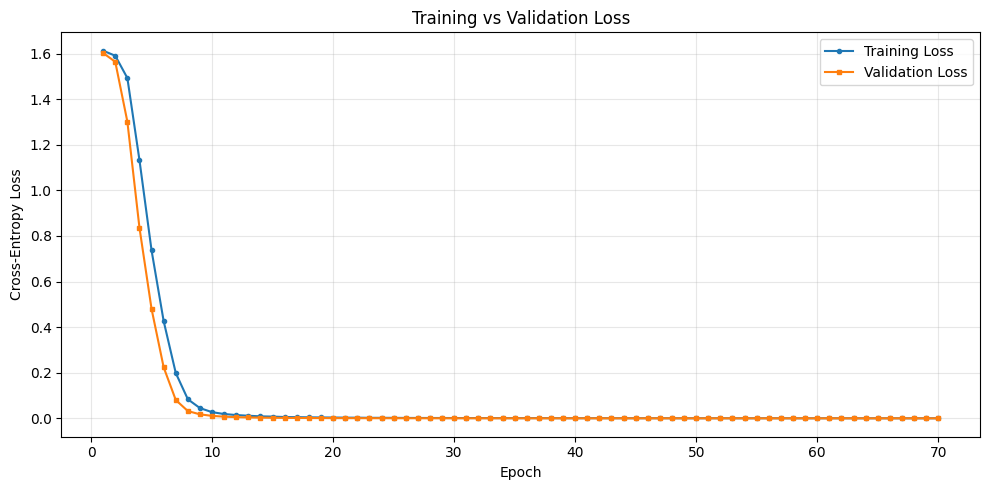

Lowest training loss: 0.0003
Lowest validation loss: 0.0001
Epoch with lowest validation loss: 69


In [14]:
# CELL 2: Training vs validation loss

import matplotlib.pyplot as plt
import pandas as pd

if not history:
    print("No training history found. Run the training cell first.")
else:
    history_df = pd.DataFrame(history)

    plt.figure(figsize=(10, 5))

    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        marker="o",
        markersize=3,
        label="Training Loss"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        marker="s",
        markersize=3,
        label="Validation Loss"
    )

    plt.title("Training vs Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("Lowest training loss:",
          round(history_df["train_loss"].min(), 4))

    best_loss_row = history_df.loc[
        history_df["val_loss"].idxmin()
    ]

    print("Lowest validation loss:",
          round(best_loss_row["val_loss"], 4))

    print("Epoch with lowest validation loss:",
          int(best_loss_row["epoch"]))

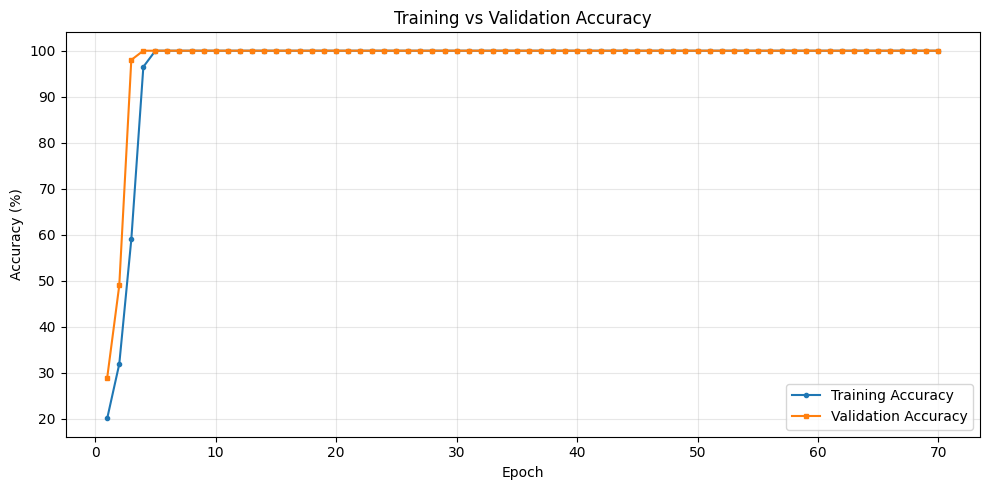

Final training accuracy: 100.00%
Final validation accuracy: 100.00%


In [15]:
# CELL 3: Accuracy comparison

if not history:
    print("No training history found.")
else:
    history_df = pd.DataFrame(history)

    plt.figure(figsize=(10, 5))

    plt.plot(
        history_df["epoch"],
        history_df["train_accuracy"] * 100,
        marker="o",
        markersize=3,
        label="Training Accuracy"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_accuracy"] * 100,
        marker="s",
        markersize=3,
        label="Validation Accuracy"
    )

    plt.title("Training vs Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"Final training accuracy: "
          f"{history_df['train_accuracy'].iloc[-1] * 100:.2f}%")

    print(f"Final validation accuracy: "
          f"{history_df['val_accuracy'].iloc[-1] * 100:.2f}%")

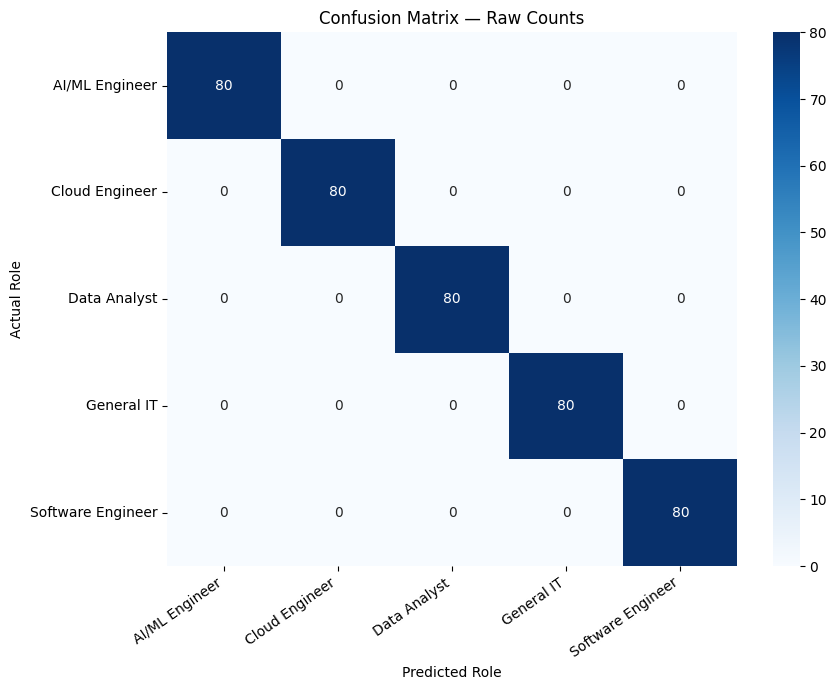

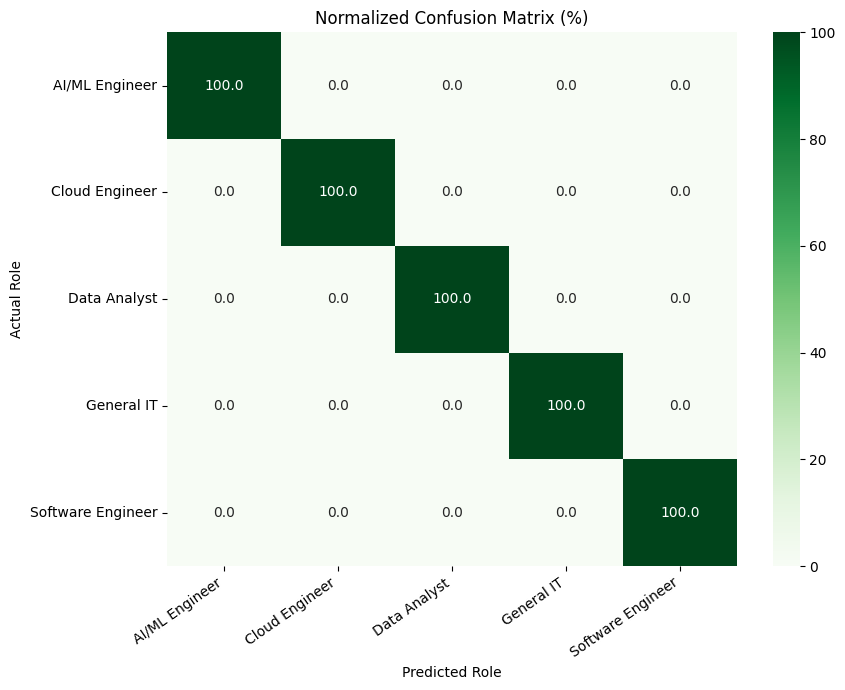

In [16]:
# CELL 4: Confusion matrix comparison

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch

# Load the best model saved during training
model.load_state_dict(
    torch.load(BEST_PATH, map_location=DEVICE, weights_only=True)
)

model.eval()

all_predictions = []
all_actual = []

with torch.no_grad():
    for ids, mask, num, y in loaders["test"]:
        ids = ids.to(DEVICE)
        mask = mask.to(DEVICE)
        num = num.to(DEVICE)

        logits = model(ids, mask, num)
        predictions = logits.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_actual.extend(y.numpy())

cm = confusion_matrix(
    all_actual,
    all_predictions,
    labels=list(range(len(ROLES)))
)

# Raw counts
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=ROLES,
    yticklabels=ROLES,
    cmap="Blues"
)

plt.title("Confusion Matrix — Raw Counts")
plt.xlabel("Predicted Role")
plt.ylabel("Actual Role")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Row-normalized percentages
row_totals = cm.sum(axis=1, keepdims=True)

cm_percent = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
) * 100

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    xticklabels=ROLES,
    yticklabels=ROLES,
    cmap="Greens",
    vmin=0,
    vmax=100
)

plt.title("Normalized Confusion Matrix (%)")
plt.xlabel("Predicted Role")
plt.ylabel("Actual Role")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
!pip -q install seaborn

Overall test accuracy: 100.00%


,Role,Precision (%),Recall (%),F1-Score (%),Test Samples
0,AI/ML Engineer,100.00,100.00,100.00,80
1,Cloud Engineer,100.00,100.00,100.00,80
2,Data Analyst,100.00,100.00,100.00,80
3,General IT,100.00,100.00,100.00,80
4,Software Engineer,100.00,100.00,100.00,80


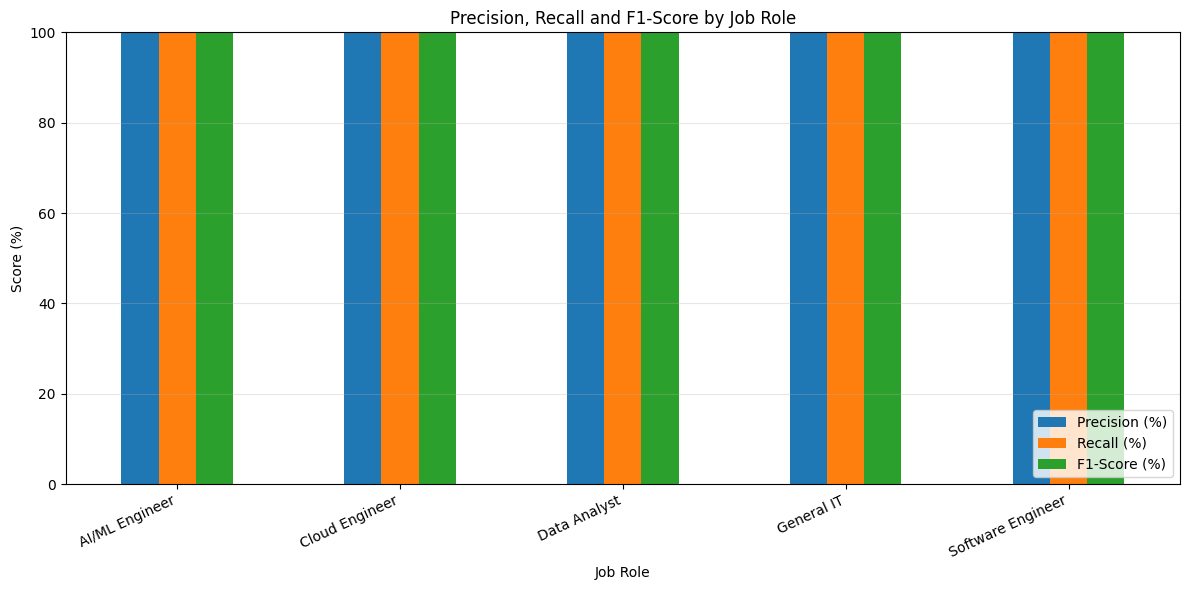

In [18]:
# CELL 5: Classification score comparison

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)
import pandas as pd
import matplotlib.pyplot as plt

labels_list = list(range(len(ROLES)))

precision, recall, f1, support = precision_recall_fscore_support(
    all_actual,
    all_predictions,
    labels=labels_list,
    zero_division=0
)

score_df = pd.DataFrame({
    "Role": ROLES,
    "Precision (%)": precision * 100,
    "Recall (%)": recall * 100,
    "F1-Score (%)": f1 * 100,
    "Test Samples": support
})

print("Overall test accuracy:",
      f"{accuracy_score(all_actual, all_predictions) * 100:.2f}%")

display(
    score_df.style.format({
        "Precision (%)": "{:.2f}",
        "Recall (%)": "{:.2f}",
        "F1-Score (%)": "{:.2f}"
    })
)

# Visual comparison of metrics for each role
score_df.set_index("Role")[
    ["Precision (%)", "Recall (%)", "F1-Score (%)"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 100)
)

plt.title("Precision, Recall and F1-Score by Job Role")
plt.ylabel("Score (%)")
plt.xlabel("Job Role")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

,Metric,Score (%)
0,Accuracy,100.0
1,Macro Precision,100.0
2,Macro Recall,100.0
3,Macro F1-Score,100.0


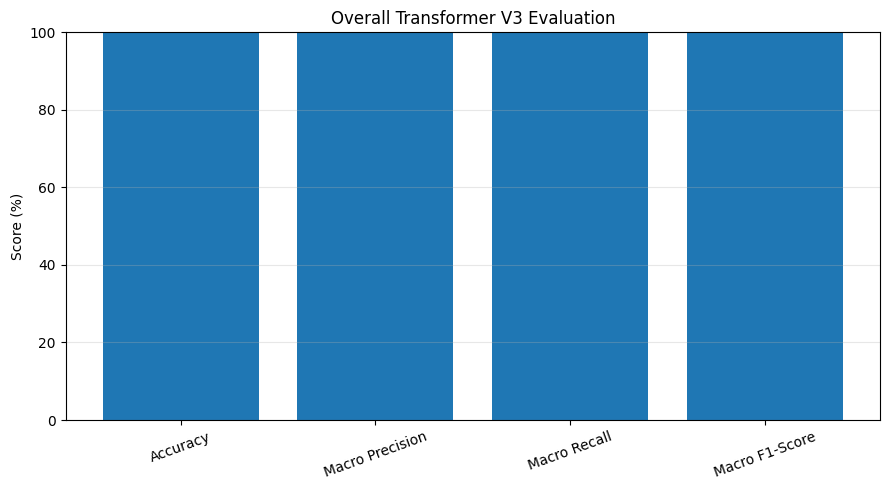

In [19]:
# CELL 6: Overall model evaluation scores

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import matplotlib.pyplot as plt

overall_scores = {
    "Accuracy": accuracy_score(all_actual, all_predictions),
    "Macro Precision": precision_score(
        all_actual, all_predictions,
        labels=list(range(len(ROLES))),
        average="macro",
        zero_division=0
    ),
    "Macro Recall": recall_score(
        all_actual, all_predictions,
        labels=list(range(len(ROLES))),
        average="macro",
        zero_division=0
    ),
    "Macro F1-Score": f1_score(
        all_actual, all_predictions,
        labels=list(range(len(ROLES))),
        average="macro",
        zero_division=0
    )
}

overall_df = pd.DataFrame({
    "Metric": list(overall_scores.keys()),
    "Score (%)": [
        value * 100 for value in overall_scores.values()
    ]
})

display(overall_df.round(2))

plt.figure(figsize=(9, 5))
plt.bar(overall_df["Metric"], overall_df["Score (%)"])

plt.title("Overall Transformer V3 Evaluation")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# CELL 7: Best vs final training performance

if not history:
    print("No completed training epochs found.")
else:
    history_df = pd.DataFrame(history)

    best_accuracy_row = history_df.loc[
        history_df["val_accuracy"].idxmax()
    ]

    final_row = history_df.iloc[-1]

    comparison_df = pd.DataFrame({
        "Metric": [
            "Training Loss",
            "Validation Loss",
            "Training Accuracy (%)",
            "Validation Accuracy (%)"
        ],
        "Best Validation Epoch": [
            best_accuracy_row["train_loss"],
            best_accuracy_row["val_loss"],
            best_accuracy_row["train_accuracy"] * 100,
            best_accuracy_row["val_accuracy"] * 100
        ],
        "Final Epoch": [
            final_row["train_loss"],
            final_row["val_loss"],
            final_row["train_accuracy"] * 100,
            final_row["val_accuracy"] * 100
        ]
    })

    display(comparison_df.round(4))

    print(
        "Highest validation accuracy occurred at epoch:",
        int(best_accuracy_row["epoch"])
    )

,Metric,Best Validation Epoch,Final Epoch
0,Training Loss,1.1326,0.0003
1,Validation Loss,0.8358,0.0001
2,Training Accuracy (%),96.5000,100.0000
3,Validation Accuracy (%),100.0000,100.0000


Highest validation accuracy occurred at epoch: 4


Predicted role: AI/ML Engineer
Highest model confidence: 99.99%


,Role,Confidence (%)
0,AI/ML Engineer,99.989998
1,Cloud Engineer,0.000000
2,Data Analyst,0.000000
3,General IT,0.000000
4,Software Engineer,0.000000


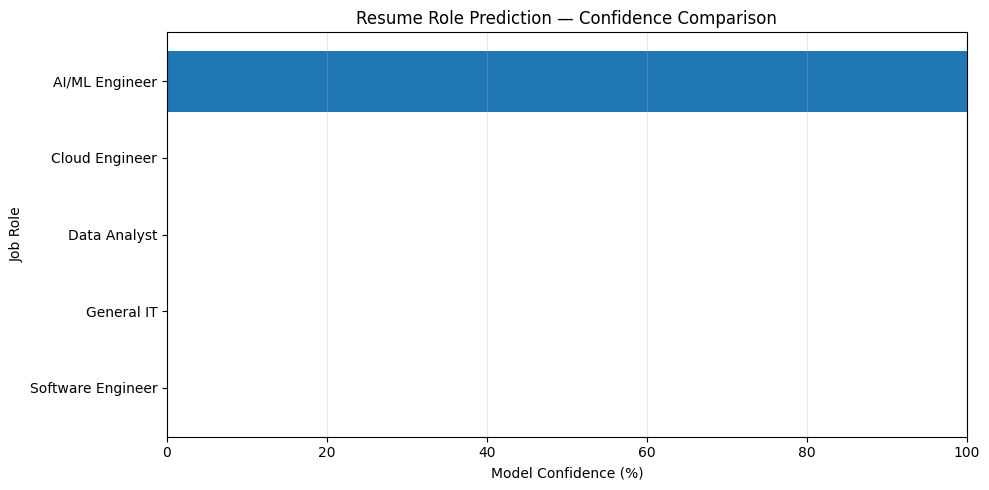

In [21]:
# CELL 8: Role-wise prediction confidence comparison

example = """
Machine Learning Engineer with 1.5 years of experience.
Python, TensorFlow, PyTorch, SQL, AWS.
B.Tech in Computer Science.
4 projects and TensorFlow certification.
"""

features, predicted_role, confidence, probabilities = predict(example)

confidence_df = pd.DataFrame({
    "Role": list(probabilities.keys()),
    "Confidence (%)": list(probabilities.values())
}).sort_values("Confidence (%)", ascending=False)

print("Predicted role:", predicted_role)
print(f"Highest model confidence: {confidence:.2f}%")

display(confidence_df.round(2))

plt.figure(figsize=(10, 5))
plt.barh(
    confidence_df["Role"],
    confidence_df["Confidence (%)"]
)

plt.title("Resume Role Prediction — Confidence Comparison")
plt.xlabel("Model Confidence (%)")
plt.ylabel("Job Role")
plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()